# Crop Demand & Price Forecasting and route optimization.

##Cell 01 : Install Important libraries

In [1]:
# ============================================================
# CELL 1: INSTALL REQUIRED LIBRARIES
# ============================================================

# XGBoost = main machine learning algorithm
# scikit-learn = preprocessing, train/test split, evaluation
# pandas = data handling
# numpy = numerical calculations
# matplotlib/seaborn = visualization
# joblib = save trained ML models

!pip install -q xgboost pandas numpy scikit-learn matplotlib seaborn joblib

---

### Cell 2 — Import libraries

In [39]:
# ============================================================
# CELL 2: IMPORT IMPORTANT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

# Machine Learning
from xgboost import XGBRegressor

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Save/load ML models
import joblib

# Display settings
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


---

# Cell 3 — Upload your dataset

In [40]:
# ============================================================
# CELL 3: UPLOAD CSV DATASET
# ============================================================

from google.colab import files

# Open the file upload window
uploaded = files.upload()

print("File uploaded successfully!")

Saving soybean_madhya_pradesh_10000_enhanced.csv to soybean_madhya_pradesh_10000_enhanced (1).csv
File uploaded successfully!


After running this cell, select:

```text
soybean_madhya_pradesh_10000_enhanced.csv
```

---

# Cell 4 — Load dataset

In [41]:
# ============================================================
# CELL 4: LOAD DATASET
# ============================================================

# Get the uploaded filename automatically
file_name = list(uploaded.keys())[0]

# Read CSV
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

# Display first 5 rows
display(df.head())

Dataset loaded successfully!


,crop_name,state,district,market_name,month,quantity_kg,demand_kg,supply_kg,farmer_price_per_kg,mandi_price_per_kg,wholesale_price_per_kg,retailer_price_per_kg,consumer_price_per_kg,num_intermediaries,transport_cost_per_kg,storage_cost_per_kg,rainfall_mm,temperature_c,fuel_price,distance_to_mandi_km,quality_grade,farmer_income_per_kg,price_gap,farmer_share_percent,recommended_price_per_kg,Previous Price,Competitor Price,Stock,Season,Weather,Festival,Previous Demand,Farmer Selling Quantity
0,Soybean,Madhya Pradesh,Ujjain,Ujjain Mandi,9,3511,4563,3267,63.89,69.06,71.93,82.12,86.15,2,2.28,2.52,1211.0,31.4,97.18,29.0,A,63.05,22.27,74.16,60.31,70.34,63.75,2148,Kharif Harvest,Heavy Rain,Ganesh Chaturthi,4867,2718
1,Soybean,Madhya Pradesh,Dhar,Dhar Mandi,9,2846,3091,3142,47.11,52.22,55.78,63.83,70.33,3,5.52,2.33,789.0,28.2,97.25,94.0,A,45.66,23.22,66.99,47.61,49.86,54.55,1966,Kharif Harvest,Rainy,Ganesh Chaturthi,2540,2557
2,Soybean,Madhya Pradesh,Bhopal,Bhopal Mandi,11,2095,2056,1534,39.02,45.30,48.64,52.65,55.93,4,1.48,1.20,759.0,25.4,94.35,12.0,C,38.55,16.91,69.77,39.15,46.14,44.74,1263,Kharif Harvest,Rainy,Diwali,1915,1707
3,Soybean,Madhya Pradesh,Neemuch,Neemuch Mandi,11,1791,2578,2090,59.24,66.14,70.33,78.74,87.43,3,5.42,0.67,1280.2,20.3,93.47,99.3,B,58.06,28.18,67.76,59.74,69.36,64.33,1419,Kharif Harvest,Heavy Rain,Diwali,2357,1506
4,Soybean,Madhya Pradesh,Mandsaur,Mandsaur Mandi,11,582,774,756,54.25,60.37,65.20,75.35,80.40,3,4.70,0.85,868.0,26.3,102.84,80.9,A,53.18,26.15,67.48,54.75,54.47,59.87,100,Kharif Harvest,Rainy,Diwali,1096,391


---

# Cell 5 — Understand the dataset

In [42]:
# ============================================================
# CELL 5: BASIC DATASET INFORMATION
# ============================================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 10000
Number of columns: 33

Column Names:
['crop_name', 'state', 'district', 'market_name', 'month', 'quantity_kg', 'demand_kg', 'supply_kg', 'farmer_price_per_kg', 'mandi_price_per_kg', 'wholesale_price_per_kg', 'retailer_price_per_kg', 'consumer_price_per_kg', 'num_intermediaries', 'transport_cost_per_kg', 'storage_cost_per_kg', 'rainfall_mm', 'temperature_c', 'fuel_price', 'distance_to_mandi_km', 'quality_grade', 'farmer_income_per_kg', 'price_gap', 'farmer_share_percent', 'recommended_price_per_kg', 'Previous Price', 'Competitor Price', 'Stock', 'Season', 'Weather', 'Festival', 'Previous Demand', 'Farmer Selling Quantity']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   crop_name                 10000 non-null  object 
 1   state                     10000 non-null  object

---

# Cell 6 — Check missing values

In [43]:
# ============================================================
# CELL 6: CHECK MISSING VALUES
# ============================================================

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
crop_name                   0
state                       0
district                    0
market_name                 0
month                       0
quantity_kg                 0
demand_kg                   0
supply_kg                   0
farmer_price_per_kg         0
mandi_price_per_kg          0
wholesale_price_per_kg      0
retailer_price_per_kg       0
consumer_price_per_kg       0
num_intermediaries          0
transport_cost_per_kg       0
storage_cost_per_kg         0
rainfall_mm                 0
temperature_c               0
fuel_price                  0
distance_to_mandi_km        0
quality_grade               0
farmer_income_per_kg        0
price_gap                   0
farmer_share_percent        0
recommended_price_per_kg    0
Previous Price              0
Competitor Price            0
Stock                       0
Season                      0
Weather                     0
Festival                    0
Previous Demand             0
Farmer Se

If your output is:

```text
Total missing values: 0
```

then your dataset doesn't contain missing values.

---

# Cell 7 — Statistical analysis

In [44]:
# ============================================================
# CELL 7: STATISTICAL SUMMARY
# ============================================================

# describe() gives:
# count
# mean
# standard deviation
# minimum
# maximum
# etc.

display(df.describe())

,month,quantity_kg,demand_kg,supply_kg,farmer_price_per_kg,mandi_price_per_kg,wholesale_price_per_kg,retailer_price_per_kg,consumer_price_per_kg,num_intermediaries,transport_cost_per_kg,storage_cost_per_kg,rainfall_mm,temperature_c,fuel_price,distance_to_mandi_km,farmer_income_per_kg,price_gap,farmer_share_percent,recommended_price_per_kg,Previous Price,Competitor Price,Stock,Previous Demand,Farmer Selling Quantity
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,8.760900,2222.204400,2499.476600,2223.626200,51.424796,57.122260,61.144511,68.325584,73.779470,2.80570,3.900969,1.932154,850.072420,27.068180,96.009827,77.364250,50.354808,22.354745,69.867173,50.812986,57.112990,57.440249,1575.73500,2496.940900,1887.387200
std,3.845986,1597.638351,1889.430141,1670.013334,6.603931,7.320535,8.184887,9.174847,10.040797,1.08077,1.691216,0.896499,217.426365,3.948393,4.003709,41.800293,6.617265,4.771162,3.741101,6.709722,8.070692,7.804483,1178.64987,1912.180454,1366.685346
min,1.000000,200.000000,174.000000,149.000000,32.000000,34.170000,35.470000,39.030000,42.550000,1.00000,1.130000,0.400000,350.000000,18.000000,80.800000,5.000000,30.280000,9.790000,58.360000,29.790000,32.190000,33.810000,100.00000,200.000000,100.000000
25%,9.000000,1172.000000,1280.000000,1145.000000,46.850000,52.087500,55.437500,61.910000,66.720000,2.00000,2.490000,1.150000,700.300000,24.300000,93.330000,41.400000,45.767500,18.970000,67.217500,46.170000,51.437500,52.020000,819.00000,1262.000000,998.000000
50%,10.000000,1802.500000,2006.000000,1786.000000,51.290000,56.890000,60.835000,67.980000,73.320000,3.00000,3.760000,1.925000,849.450000,27.100000,95.990000,76.700000,50.220000,21.920000,69.820000,50.560000,56.745000,57.190000,1283.00000,1989.000000,1542.500000
75%,11.000000,2779.500000,3127.000000,2775.000000,55.920000,61.970000,66.530000,74.352500,80.380000,4.00000,5.120000,2.700000,998.825000,29.700000,98.690000,113.525000,54.870000,25.370000,72.410000,55.242500,62.430000,62.550000,1990.25000,3134.250000,2365.000000
max,12.000000,15000.000000,21040.000000,18463.000000,68.000000,79.750000,87.720000,99.990000,111.790000,5.00000,8.470000,3.500000,1400.000000,38.000000,113.450000,150.000000,67.610000,43.790000,81.940000,76.020000,87.630000,84.200000,13027.00000,22575.000000,13469.000000


---

# Cell 8 — Check categorical columns

In [45]:
# ============================================================
# CELL 8: IDENTIFY CATEGORICAL AND NUMERICAL FEATURES
# ============================================================

# Categorical columns
categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['crop_name', 'state', 'district', 'market_name', 'quality_grade', 'Season', 'Weather', 'Festival']

Numerical columns:
['month', 'quantity_kg', 'demand_kg', 'supply_kg', 'farmer_price_per_kg', 'mandi_price_per_kg', 'wholesale_price_per_kg', 'retailer_price_per_kg', 'consumer_price_per_kg', 'num_intermediaries', 'transport_cost_per_kg', 'storage_cost_per_kg', 'rainfall_mm', 'temperature_c', 'fuel_price', 'distance_to_mandi_km', 'farmer_income_per_kg', 'price_gap', 'farmer_share_percent', 'recommended_price_per_kg', 'Previous Price', 'Competitor Price', 'Stock', 'Previous Demand', 'Farmer Selling Quantity']


You should see categorical columns similar to:

```text
crop
district
market
Season
Weather
Festival
```

depending on your dataset.

---

# Cell 9 — Remove unnecessary columns

Before training, we don't want ID-type columns or columns that shouldn't be used as predictors.

In [46]:
# ============================================================
# CELL 9: REMOVE UNNECESSARY COLUMNS
# ============================================================

# Make a copy so original dataset remains unchanged
data = df.copy()

# Columns that are generally identifiers rather than useful
# predictive variables.
possible_id_columns = [
    "id",
    "ID",
    "date_id"
]

# Remove only columns that actually exist
columns_to_remove = [
    col for col in possible_id_columns
    if col in data.columns
]

data.drop(columns=columns_to_remove, inplace=True)

print("Removed columns:", columns_to_remove)

print("\nRemaining columns:")
print(data.columns.tolist())

Removed columns: []

Remaining columns:
['crop_name', 'state', 'district', 'market_name', 'month', 'quantity_kg', 'demand_kg', 'supply_kg', 'farmer_price_per_kg', 'mandi_price_per_kg', 'wholesale_price_per_kg', 'retailer_price_per_kg', 'consumer_price_per_kg', 'num_intermediaries', 'transport_cost_per_kg', 'storage_cost_per_kg', 'rainfall_mm', 'temperature_c', 'fuel_price', 'distance_to_mandi_km', 'quality_grade', 'farmer_income_per_kg', 'price_gap', 'farmer_share_percent', 'recommended_price_per_kg', 'Previous Price', 'Competitor Price', 'Stock', 'Season', 'Weather', 'Festival', 'Previous Demand', 'Farmer Selling Quantity']


---

# Cell 10 — Define targets

This is a very important step.

We have **two different prediction problems**.

### Target 1

```text
Demand
```

### Target 2

```text
Price
```

In [47]:
# ============================================================
# CELL 10: DEFINE TARGET VARIABLES
# ============================================================

# Demand prediction target
DEMAND_TARGET = "demand_kg"

# Price prediction target
PRICE_TARGET = "mandi_price_per_kg"

# Check that both targets exist
if DEMAND_TARGET not in data.columns:
    raise ValueError(f"{DEMAND_TARGET} not found in dataset!")

if PRICE_TARGET not in data.columns:
    raise ValueError(f"{PRICE_TARGET} not found in dataset!")

print("Demand target:", DEMAND_TARGET)
print("Price target:", PRICE_TARGET)

Demand target: demand_kg
Price target: mandi_price_per_kg


---

# 11. Demand Prediction Model

Now we build our first XGBoost model.

## Features

We should NOT use the target itself as an input.

In [48]:
# ============================================================
# CELL 11: CREATE DEMAND DATASET
# ============================================================

# Copy dataset
demand_data = data.copy()

# Demand target
y_demand = demand_data[DEMAND_TARGET]

# Remove target columns from input features
# Price is also removed here to avoid creating a direct
# target leakage relationship with the current price.
X_demand = demand_data.drop(
    columns=[
        DEMAND_TARGET,
        PRICE_TARGET
    ],
    errors="ignore"
)

print("Demand feature shape:", X_demand.shape)
print("Demand target shape:", y_demand.shape)

display(X_demand.head())

Demand feature shape: (10000, 31)
Demand target shape: (10000,)


,crop_name,state,district,market_name,month,quantity_kg,supply_kg,farmer_price_per_kg,wholesale_price_per_kg,retailer_price_per_kg,consumer_price_per_kg,num_intermediaries,transport_cost_per_kg,storage_cost_per_kg,rainfall_mm,temperature_c,fuel_price,distance_to_mandi_km,quality_grade,farmer_income_per_kg,price_gap,farmer_share_percent,recommended_price_per_kg,Previous Price,Competitor Price,Stock,Season,Weather,Festival,Previous Demand,Farmer Selling Quantity
0,Soybean,Madhya Pradesh,Ujjain,Ujjain Mandi,9,3511,3267,63.89,71.93,82.12,86.15,2,2.28,2.52,1211.0,31.4,97.18,29.0,A,63.05,22.27,74.16,60.31,70.34,63.75,2148,Kharif Harvest,Heavy Rain,Ganesh Chaturthi,4867,2718
1,Soybean,Madhya Pradesh,Dhar,Dhar Mandi,9,2846,3142,47.11,55.78,63.83,70.33,3,5.52,2.33,789.0,28.2,97.25,94.0,A,45.66,23.22,66.99,47.61,49.86,54.55,1966,Kharif Harvest,Rainy,Ganesh Chaturthi,2540,2557
2,Soybean,Madhya Pradesh,Bhopal,Bhopal Mandi,11,2095,1534,39.02,48.64,52.65,55.93,4,1.48,1.20,759.0,25.4,94.35,12.0,C,38.55,16.91,69.77,39.15,46.14,44.74,1263,Kharif Harvest,Rainy,Diwali,1915,1707
3,Soybean,Madhya Pradesh,Neemuch,Neemuch Mandi,11,1791,2090,59.24,70.33,78.74,87.43,3,5.42,0.67,1280.2,20.3,93.47,99.3,B,58.06,28.18,67.76,59.74,69.36,64.33,1419,Kharif Harvest,Heavy Rain,Diwali,2357,1506
4,Soybean,Madhya Pradesh,Mandsaur,Mandsaur Mandi,11,582,756,54.25,65.20,75.35,80.40,3,4.70,0.85,868.0,26.3,102.84,80.9,A,53.18,26.15,67.48,54.75,54.47,59.87,100,Kharif Harvest,Rainy,Diwali,1096,391


---

# 12. Detect categorical features

In [49]:
# ============================================================
# CELL 12: DEMAND MODEL - IDENTIFY FEATURE TYPES
# ============================================================

demand_categorical = X_demand.select_dtypes(
    include=["object"]
).columns.tolist()

demand_numerical = X_demand.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:")
print(demand_categorical)

print("\nNumerical features:")
print(demand_numerical)

Categorical features:
['crop_name', 'state', 'district', 'market_name', 'quality_grade', 'Season', 'Weather', 'Festival']

Numerical features:
['month', 'quantity_kg', 'supply_kg', 'farmer_price_per_kg', 'wholesale_price_per_kg', 'retailer_price_per_kg', 'consumer_price_per_kg', 'num_intermediaries', 'transport_cost_per_kg', 'storage_cost_per_kg', 'rainfall_mm', 'temperature_c', 'fuel_price', 'distance_to_mandi_km', 'farmer_income_per_kg', 'price_gap', 'farmer_share_percent', 'recommended_price_per_kg', 'Previous Price', 'Competitor Price', 'Stock', 'Previous Demand', 'Farmer Selling Quantity']


---

# 13. Train/test split

In [50]:
# ============================================================
# CELL 13: TRAIN-TEST SPLIT FOR DEMAND MODEL
# ============================================================

X_train_demand, X_test_demand, y_train_demand, y_test_demand = train_test_split(
    X_demand,
    y_demand,
    test_size=0.20,       # 80% training, 20% testing
    random_state=42
)

print("Training samples:", len(X_train_demand))
print("Testing samples:", len(X_test_demand))

Training samples: 8000
Testing samples: 2000


---

# 14. One-Hot Encoding

XGBoost cannot directly understand text such as:

```text
Kharif Harvest
Rainy
Diwali
```

So we convert categorical values into numerical values.

In [52]:
# ============================================================
# CELL 14: PREPROCESS DEMAND FEATURES
# ============================================================

demand_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            demand_categorical
        ),
        (
            "numerical",
            "passthrough",
            demand_numerical
        )
    ]
)

# Fit preprocessing on training data
X_train_demand_processed = demand_preprocessor.fit_transform(
    X_train_demand
)

# Transform testing data
X_test_demand_processed = demand_preprocessor.transform(
    X_test_demand
)

print(
    "Processed training shape:",
    X_train_demand_processed.shape
)

print(
    "Processed testing shape:",
    X_test_demand_processed.shape
)

Processed training shape: (8000, 60)
Processed testing shape: (2000, 60)


---

# 15. Train XGBoost Demand Model ⭐

In [53]:
# ============================================================
# CELL 15: TRAIN XGBOOST DEMAND MODEL
# ============================================================

demand_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,

    # Objective for numerical regression
    objective="reg:squarederror",

    # Reproducibility
    random_state=42,

    # CPU training
    n_jobs=-1
)

# Train model
demand_model.fit(
    X_train_demand_processed,
    y_train_demand
)

print("XGBoost Demand Model trained successfully!")

XGBoost Demand Model trained successfully!


---

# 16. Demand prediction

In [54]:
# ============================================================
# CELL 16: PREDICT DEMAND
# ============================================================

# Predict demand for test data
demand_predictions = demand_model.predict(
    X_test_demand_processed
)

# Display first predictions
comparison_demand = pd.DataFrame({
    "Actual Demand": y_test_demand.values,
    "Predicted Demand": demand_predictions
})

display(comparison_demand.head(10))

,Actual Demand,Predicted Demand
0,5207,4921.878418
1,1635,1571.800415
2,2856,2452.593506
3,1917,2122.168945
4,1689,1872.451172
5,1500,1636.830200
6,811,825.065369
7,2022,2191.126709
8,1054,1080.730713
9,675,688.449341


---

# 17. Evaluate Demand Model

In [55]:
# ============================================================
# CELL 17: DEMAND MODEL EVALUATION
# ============================================================

mae_demand = mean_absolute_error(
    y_test_demand,
    demand_predictions
)

rmse_demand = np.sqrt(
    mean_squared_error(
        y_test_demand,
        demand_predictions
    )
)

r2_demand = r2_score(
    y_test_demand,
    demand_predictions
)

print("================================")
print("DEMAND MODEL PERFORMANCE")
print("================================")

print(f"MAE  : {mae_demand:.2f} kg")
print(f"RMSE : {rmse_demand:.2f} kg")
print(f"R²   : {r2_demand:.4f}")

DEMAND MODEL PERFORMANCE
MAE  : 176.81 kg
RMSE : 271.95 kg
R²   : 0.9756


### Understanding these metrics

```text
MAE
↓
Average prediction error

RMSE
↓
Penalizes large errors

R²
↓
How well model explains variation
```

For example:

```text
R² = 0.92
```

would mean the model explains approximately 92% of the variation in the target on that test set.

---

# 18. Demand prediction graph

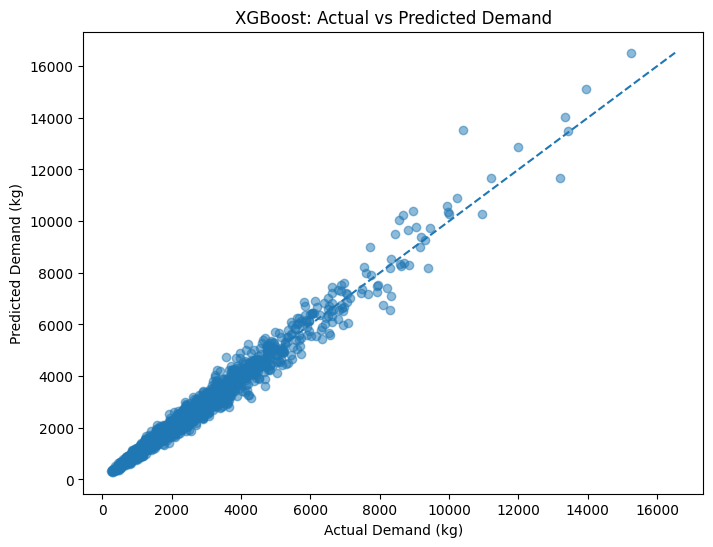

In [56]:
# ============================================================
# CELL 18: ACTUAL VS PREDICTED DEMAND
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_demand,
    demand_predictions,
    alpha=0.5
)

# Perfect prediction line
minimum = min(
    y_test_demand.min(),
    demand_predictions.min()
)

maximum = max(
    y_test_demand.max(),
    demand_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Demand (kg)")
plt.ylabel("Predicted Demand (kg)")
plt.title("XGBoost: Actual vs Predicted Demand")

plt.show()

The closer the points are to the diagonal line, the better the predictions.

---

# 19. Price Prediction Model

Now we create the second XGBoost model.

There is one important design decision here.

We want the price model to know the **predicted demand**.

So we will create predicted demand for all observations using the demand model.

For a more rigorous production pipeline, you would generate these values using out-of-fold predictions during training to avoid leakage. For a first Colab prototype, we'll keep the implementation straightforward.

In [57]:
# ============================================================
# CELL 19: CREATE DATASET FOR PRICE MODEL
# ============================================================

price_data = data.copy()

# Create predicted demand for every row
all_demand_processed = demand_preprocessor.transform(
    X_demand
)

predicted_demand_all = demand_model.predict(
    all_demand_processed
)

# Add predicted demand as a feature
price_data["Predicted Demand"] = predicted_demand_all

# Target
y_price = price_data[PRICE_TARGET]

# Features
X_price = price_data.drop(
    columns=[
        PRICE_TARGET,
        DEMAND_TARGET
    ],
    errors="ignore"
)

print("Price feature shape:", X_price.shape)
print("Price target shape:", y_price.shape)

Price feature shape: (10000, 32)
Price target shape: (10000,)


---

# 20. Price model feature types

In [58]:
# ============================================================
# CELL 20: PRICE MODEL FEATURE TYPES
# ============================================================

price_categorical = X_price.select_dtypes(
    include=["object"]
).columns.tolist()

price_numerical = X_price.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:")
print(price_categorical)

print("\nNumerical features:")
print(price_numerical)

Categorical features:
['crop_name', 'state', 'district', 'market_name', 'quality_grade', 'Season', 'Weather', 'Festival']

Numerical features:
['month', 'quantity_kg', 'supply_kg', 'farmer_price_per_kg', 'wholesale_price_per_kg', 'retailer_price_per_kg', 'consumer_price_per_kg', 'num_intermediaries', 'transport_cost_per_kg', 'storage_cost_per_kg', 'rainfall_mm', 'temperature_c', 'fuel_price', 'distance_to_mandi_km', 'farmer_income_per_kg', 'price_gap', 'farmer_share_percent', 'recommended_price_per_kg', 'Previous Price', 'Competitor Price', 'Stock', 'Previous Demand', 'Farmer Selling Quantity', 'Predicted Demand']


---

# 21. Train/test split for price

In [59]:
# ============================================================
# CELL 21: PRICE TRAIN-TEST SPLIT
# ============================================================

X_train_price, X_test_price, y_train_price, y_test_price = train_test_split(
    X_price,
    y_price,
    test_size=0.20,
    random_state=42
)

print("Price training samples:", len(X_train_price))
print("Price testing samples:", len(X_test_price))

Price training samples: 8000
Price testing samples: 2000


---

# 22. Preprocess price features

In [60]:
# ============================================================
# CELL 22: PREPROCESS PRICE FEATURES
# ============================================================

price_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            price_categorical
        ),
        (
            "numerical",
            "passthrough",
            price_numerical
        )
    ]
)

X_train_price_processed = price_preprocessor.fit_transform(
    X_train_price
)

X_test_price_processed = price_preprocessor.transform(
    X_test_price
)

print(
    "Processed price training shape:",
    X_train_price_processed.shape
)

print(
    "Processed price testing shape:",
    X_test_price_processed.shape
)

Processed price training shape: (8000, 61)
Processed price testing shape: (2000, 61)


---

# 23. Train XGBoost Price Model ⭐

In [61]:
# ============================================================
# CELL 23: TRAIN XGBOOST PRICE MODEL
# ============================================================

price_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="reg:squarederror",

    random_state=42,

    n_jobs=-1
)

price_model.fit(
    X_train_price_processed,
    y_train_price
)

print("XGBoost Price Model trained successfully!")

XGBoost Price Model trained successfully!


---

# 24. Predict price

In [62]:
# ============================================================
# CELL 24: PREDICT PRICE
# ============================================================

price_predictions = price_model.predict(
    X_test_price_processed
)

price_comparison = pd.DataFrame({
    "Actual Price": y_test_price.values,
    "Predicted Price": price_predictions
})

display(price_comparison.head(10))

,Actual Price,Predicted Price
0,71.91,71.822372
1,64.45,64.235252
2,63.70,64.200844
3,46.87,46.725307
4,50.92,51.094196
5,43.43,43.522572
6,56.70,56.037811
7,53.68,53.091057
8,57.50,57.560726
9,48.03,48.251587


---

# 25. Evaluate Price Model

In [63]:
# ============================================================
# CELL 25: PRICE MODEL EVALUATION
# ============================================================

mae_price = mean_absolute_error(
    y_test_price,
    price_predictions
)

rmse_price = np.sqrt(
    mean_squared_error(
        y_test_price,
        price_predictions
    )
)

r2_price = r2_score(
    y_test_price,
    price_predictions
)

print("================================")
print("PRICE MODEL PERFORMANCE")
print("================================")

print(f"MAE  : ₹{mae_price:.2f}/kg")
print(f"RMSE : ₹{rmse_price:.2f}/kg")
print(f"R²   : {r2_price:.4f}")

PRICE MODEL PERFORMANCE
MAE  : ₹0.29/kg
RMSE : ₹0.36/kg
R²   : 0.9976


---

# 26. Price prediction graph

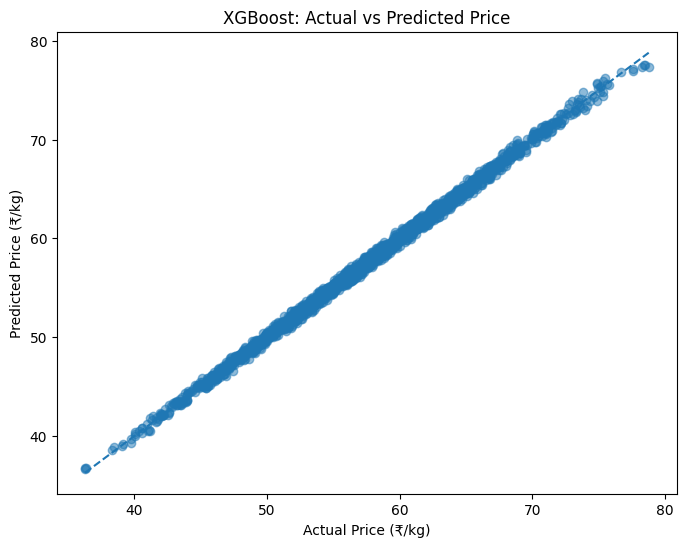

In [64]:
# ============================================================
# CELL 26: ACTUAL VS PREDICTED PRICE
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_price,
    price_predictions,
    alpha=0.5
)

minimum = min(
    y_test_price.min(),
    price_predictions.min()
)

maximum = max(
    y_test_price.max(),
    price_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Price (₹/kg)")
plt.ylabel("Predicted Price (₹/kg)")
plt.title("XGBoost: Actual vs Predicted Price")

plt.show()

---

# 27. Feature importance

This is useful for your hackathon presentation because you can show **what factors influence price and demand**.

In [65]:
# ============================================================
# CELL 27: DEMAND FEATURE IMPORTANCE
# ============================================================

# Get names of encoded features
feature_names_demand = demand_preprocessor.get_feature_names_out()

importance_demand = pd.DataFrame({
    "Feature": feature_names_demand,
    "Importance": demand_model.feature_importances_
})

importance_demand = importance_demand.sort_values(
    by="Importance",
    ascending=False
)

display(importance_demand.head(15))

,Feature,Importance
58,numerical__Previous Demand,0.754656
38,numerical__quantity_kg,0.154950
59,numerical__Farmer Selling Quantity,0.010813
51,numerical__farmer_income_per_kg,0.002858
53,numerical__farmer_share_percent,0.002655
40,numerical__farmer_price_per_kg,0.002580
50,numerical__distance_to_mandi_km,0.002413
55,numerical__Previous Price,0.002392
56,numerical__Competitor Price,0.002347
52,numerical__price_gap,0.002189


---

# 28. Plot demand feature importance

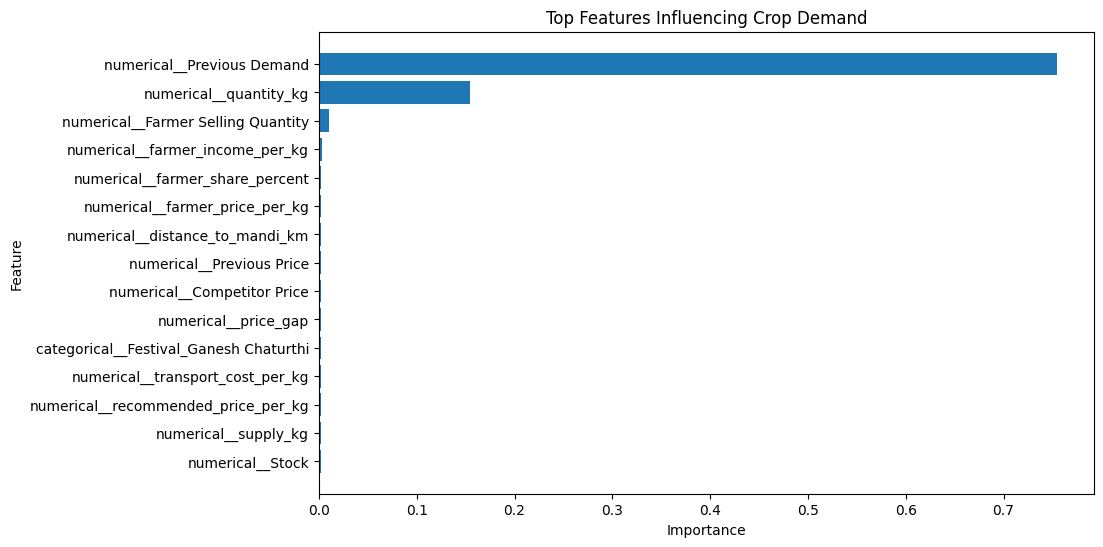

In [67]:
# ============================================================
# CELL 28: PLOT DEMAND FEATURE IMPORTANCE
# ============================================================

top_features = importance_demand.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features Influencing Crop Demand")

plt.show()

---

# 29. Price feature importance

In [68]:
# ============================================================
# CELL 29: PRICE FEATURE IMPORTANCE
# ============================================================

feature_names_price = price_preprocessor.get_feature_names_out()

importance_price = pd.DataFrame({
    "Feature": feature_names_price,
    "Importance": price_model.feature_importances_
})

importance_price = importance_price.sort_values(
    by="Importance",
    ascending=False
)

display(importance_price.head(15))

,Feature,Importance
41,numerical__wholesale_price_per_kg,0.833088
54,numerical__recommended_price_per_kg,0.102957
40,numerical__farmer_price_per_kg,0.034132
51,numerical__farmer_income_per_kg,0.022369
42,numerical__retailer_price_per_kg,0.000838
56,numerical__Competitor Price,0.000559
44,numerical__num_intermediaries,0.000497
53,numerical__farmer_share_percent,0.000431
55,numerical__Previous Price,0.000365
45,numerical__transport_cost_per_kg,0.000165


---

# 30. Save your models

You will eventually use these models in a Streamlit application.

In [69]:
# ============================================================
# CELL 30: SAVE TRAINED MODELS
# ============================================================

# Save demand model
joblib.dump(
    demand_model,
    "xgboost_demand_model.pkl"
)

# Save price model
joblib.dump(
    price_model,
    "xgboost_price_model.pkl"
)

# Save preprocessing objects
joblib.dump(
    demand_preprocessor,
    "demand_preprocessor.pkl"
)

joblib.dump(
    price_preprocessor,
    "price_preprocessor.pkl"
)

print("All models and preprocessors saved!")

All models and preprocessors saved!


---

# 31. Download models

In [71]:
# ============================================================
# CELL 31: DOWNLOAD MODELS
# ============================================================

from google.colab import files

files.download("xgboost_demand_model.pkl")
files.download("xgboost_price_model.pkl")

files.download("demand_preprocessor.pkl")
files.download("price_preprocessor.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# 32. Create prediction function

Now we create the part that your future Streamlit app can use.

In [72]:
# ============================================================
# CELL 32: COMPLETE DEMAND + PRICE PREDICTION FUNCTION
# ============================================================

def predict_crop_demand_price(input_data):
    """
    Predict crop demand and market price.

    input_data:
        pandas DataFrame containing one or more observations.

    Returns:
        Predicted demand and predicted price.
    """

    # -----------------------------
    # STEP 1: Demand prediction
    # -----------------------------

    demand_input = input_data.drop(
        columns=[
            DEMAND_TARGET,
            PRICE_TARGET,
            "Predicted Demand"
        ],
        errors="ignore"
    )

    demand_processed = demand_preprocessor.transform(
        demand_input
    )

    predicted_demand = demand_model.predict(
        demand_processed
    )

    # -----------------------------
    # STEP 2: Add predicted demand
    # -----------------------------

    price_input = input_data.drop(
        columns=[
            DEMAND_TARGET,
            PRICE_TARGET
        ],
        errors="ignore"
    ).copy()

    price_input["Predicted Demand"] = predicted_demand

    # -----------------------------
    # STEP 3: Price prediction
    # -----------------------------

    price_processed = price_preprocessor.transform(
        price_input
    )

    predicted_price = price_model.predict(
        price_processed
    )

    # -----------------------------
    # STEP 4: Return results
    # -----------------------------

    result = pd.DataFrame({
        "Predicted Demand (kg)": predicted_demand,
        "Predicted Price (₹/kg)": predicted_price
    })

    return result

---

# 33. Test prediction

In [73]:
# ============================================================
# CELL 33: TEST THE PREDICTION SYSTEM
# ============================================================

# Take one existing row as an example
sample_input = data.drop(
    columns=[
        DEMAND_TARGET,
        PRICE_TARGET
    ],
    errors="ignore"
).iloc[[0]].copy()

# Predict
prediction = predict_crop_demand_price(
    sample_input
)

display(prediction)

,Predicted Demand (kg),Predicted Price (₹/kg)
0,4846.526367,68.654381


You should get something like:

```text
Predicted Demand     Predicted Price
------------------------------------
2850 kg              ₹63.40/kg
```

Your actual numbers will depend on your trained model.

---

# 34. Best Market Recommendation Engine

Now comes the **most important part of your project**.

The ML models predict:

```text
Demand
Price
```

Then an optimization layer determines:

```text
BEST MARKET
```

For this, your dataset needs market-specific information.

If your dataset contains:

```text
market
```

we can evaluate each market.

The basic calculation is:

```text
Gross Revenue
      =
Selling Quantity × Predicted Price

Net Revenue
      =
Gross Revenue
− Transportation Cost
− Market Fees
```

---

## Cell 34 — Market scoring function

In [74]:
# ============================================================
# CELL 34: MARKET RECOMMENDATION FUNCTION
# ============================================================

def calculate_market_profit(
    selling_quantity,
    predicted_price,
    transport_cost,
    market_fee=0
):
    """
    Calculate expected revenue and net profit
    for selling crop at a particular market.
    """

    # Total money received before expenses
    gross_revenue = (
        selling_quantity * predicted_price
    )

    # Final estimated profit after expenses
    net_profit = (
        gross_revenue
        - transport_cost
        - market_fee
    )

    return gross_revenue, net_profit

---

# 35. Example market comparison

In [75]:
# ============================================================
# CELL 35: EXAMPLE MARKET COMPARISON
# ============================================================

selling_quantity = 2000  # kg

markets = pd.DataFrame({
    "Market": [
        "Gwalior",
        "Morena",
        "Bhopal",
        "Indore"
    ],

    "Predicted Price": [
        63,
        65,
        61,
        59
    ],

    "Predicted Demand": [
        3500,
        2900,
        4000,
        4500
    ],

    "Transport Cost": [
        3000,
        5000,
        15000,
        18000
    ],

    "Market Fee": [
        1000,
        1000,
        1500,
        2000
    ]
})

# Calculate gross revenue
markets["Gross Revenue"] = (
    selling_quantity *
    markets["Predicted Price"]
)

# Calculate net profit
markets["Net Profit"] = (
    markets["Gross Revenue"]
    - markets["Transport Cost"]
    - markets["Market Fee"]
)

# Sort markets by highest profit
markets = markets.sort_values(
    by="Net Profit",
    ascending=False
)

display(markets)

,Market,Predicted Price,Predicted Demand,Transport Cost,Market Fee,Gross Revenue,Net Profit
1,Morena,65,2900,5000,1000,130000,124000
0,Gwalior,63,3500,3000,1000,126000,122000
2,Bhopal,61,4000,15000,1500,122000,105500
3,Indore,59,4500,18000,2000,118000,98000


---

# 36. Automatically select best market

In [76]:
# ============================================================
# CELL 36: SELECT BEST MARKET
# ============================================================

best_market = markets.iloc[0]

print("======================================")
print("🏆 BEST MARKET RECOMMENDATION")
print("======================================")

print("Market:",
      best_market["Market"])

print(
    "Predicted Price: ₹",
    round(best_market["Predicted Price"], 2),
    "/kg"
)

print(
    "Predicted Demand:",
    round(best_market["Predicted Demand"], 2),
    "kg"
)

print(
    "Expected Gross Revenue: ₹",
    round(best_market["Gross Revenue"], 2)
)

print(
    "Expected Net Profit: ₹",
    round(best_market["Net Profit"], 2)
)

🏆 BEST MARKET RECOMMENDATION
Market: Morena
Predicted Price: ₹ 65 /kg
Predicted Demand: 2900 kg
Expected Gross Revenue: ₹ 130000
Expected Net Profit: ₹ 124000


---

# 37. Your final system

After completing the notebook, your architecture becomes:

```text
                  CSV DATASET
                       │
                       ▼
              DATA PREPROCESSING
                       │
                       ▼
              FEATURE ENGINEERING
                       │
          ┌────────────┴────────────┐
          │                         │
          ▼                         ▼
   XGBOOST DEMAND             XGBOOST PRICE
       MODEL                     MODEL
          │                         │
          ▼                         ▼
 Predicted Demand            Predicted Price
          │                         │
          └────────────┬────────────┘
                       │
                       ▼
              MARKET OPTIMIZER
                       │
                       ▼
            Revenue Calculation
                       │
                       ▼
             Transportation Cost
                       │
                       ▼
                Market Fee
                       │
                       ▼
                 NET PROFIT
                       │
                       ▼
              🏆 BEST MARKET
```

## One important improvement before calling this a final model

Your current dataset is excellent for **building the prototype**, but because some of the added columns were synthetically generated, the model can learn artificial relationships.

For a serious hackathon/real-world version, the next step should be:

```text
Real historical data
       ↓
Date + Market + District
       ↓
Historical Demand
Historical Price
Historical Stock
Weather
Festival
Transportation
       ↓
Lag Features
       ↓
XGBoost
       ↓
Demand + Price
       ↓
Market Optimization
```

Also, **do not evaluate the final model only on the same synthetic data used to generate the features**. A real held-out time period or real market data would give you a much more credible accuracy estimate.